In [3]:
import pandas as pd
import matplotlib.pyplot as plt



In [4]:
imports = pd.read_csv(r"C:\Users\racol\OneDrive\Desktop\coffee-yen-project\data\raw\japan_green_coffee_imports_2010_2026.csv")
imports.head()

,month,quantity_kg,value_thousand_yen,value_yen,yen_per_kg
0,2010-01,28031253,7217477,7217477000,257.5
1,2010-02,28358072,7224624,7224624000,254.8
2,2010-03,38966837,10448859,10448859000,268.1
3,2010-04,38096203,11229699,11229699000,294.8
4,2010-05,38514372,10952713,10952713000,284.4


In [10]:
# Folder where all the raw data files are saved
# The r in front lets Python read the Windows backslashes correctly
DATA = r"C:\Users\racol\OneDrive\Desktop\coffee-yen-project\data\raw"

In [17]:
# ---------- Arabica ----------
# Source: IMF via FRED, series PCOFFOTMUSDM, U.S. cents per pound, monthly
arabica = pd.read_csv(DATA + r"\arabica_price.csv")

# Convert dates to real dates and give columns clear names
arabica["observation_date"] = pd.to_datetime(arabica["observation_date"])
arabica = arabica.rename(columns={
    "observation_date": "month",
    "PCOFFOTMUSDM": "arabica_cents_lb"
})

# Health check: size, missing values, date range
print("ARABICA")
print("Shape:", arabica.shape)
print("Missing values:", arabica.isna().sum().sum())
print("Dates:", arabica["month"].min().date(), "to", arabica["month"].max().date())
print()

ARABICA
Shape: (193, 2)
Missing values: 0
Dates: 2010-07-01 to 2026-07-01



In [18]:
# ---------- Robusta ----------
# Source: IMF via FRED, series PCOFFROBUSDM, U.S. cents per pound, monthly
robusta = pd.read_csv(DATA + r"\robusta_price.csv")

# Convert dates to real dates and give columns clear names
robusta["observation_date"] = pd.to_datetime(robusta["observation_date"])
robusta = robusta.rename(columns={
    "observation_date": "month",
    "PCOFFROBUSDM": "robusta_cents_lb"
})

# Health check: size, missing values, date range
print("ROBUSTA")
print("Shape:", robusta.shape)
print("Missing values:", robusta.isna().sum().sum())
print("Dates:", robusta["month"].min().date(), "to", robusta["month"].max().date())
print()



ROBUSTA
Shape: (199, 2)
Missing values: 0
Dates: 2010-01-01 to 2026-07-01



In [19]:
# ---------- Yen per U.S. dollar ----------
# Source: Federal Reserve Board via FRED, series EXJPUS, monthly average
yen = pd.read_csv(DATA + r"\yendollar_rate.csv")

# Convert dates to real dates and give columns clear names
yen["observation_date"] = pd.to_datetime(yen["observation_date"])
yen = yen.rename(columns={
    "observation_date": "month",
    "EXJPUS": "yen_per_usd"
})

# Health check: size, missing values, date range
print("YEN PER DOLLAR")
print("Shape:", yen.shape)
print("Missing values:", yen.isna().sum().sum())
print("Dates:", yen["month"].min().date(), "to", yen["month"].max().date())

YEN PER DOLLAR
Shape: (201, 2)
Missing values: 0
Dates: 2010-01-01 to 2026-09-01


In [20]:
# Merge the three tables on the "month" column
# how="outer" keeps every month that appears in ANY file,
# so we can see where the files don't line up (instead of silently dropping months)
fred = (arabica
        .merge(robusta, on="month", how="outer")
        .merge(yen, on="month", how="outer"))

# Keep January 2010 onward and put the months in order
fred = fred[fred["month"] >= "2010-01-01"].sort_values("month").reset_index(drop=True)

# Health check on the merged table
print("Shape:", fred.shape)
print()
print("Missing values per column:")
print(fred.isna().sum())

# Show which months have gaps, so we know exactly where they are
fred[fred.isna().any(axis=1)]

Shape: (201, 4)

Missing values per column:
month               0
arabica_cents_lb    8
robusta_cents_lb    2
yen_per_usd         0
dtype: int64


,month,arabica_cents_lb,robusta_cents_lb,yen_per_usd
0,2010-01-01,NaN,69.939524,91.1011
1,2010-02-01,NaN,67.884500,90.1395
2,2010-03-01,NaN,67.247391,90.7161
3,2010-04-01,NaN,71.636364,93.4527
4,2010-05-01,NaN,70.723810,91.9730
5,2010-06-01,NaN,76.921818,90.8059
199,2026-08-01,NaN,NaN,158.8476
200,2026-09-01,NaN,NaN,156.4171


In [21]:
# Number of pounds in one kilogram
LB_PER_KG = 2.20462

# Step 1 and 2: U.S. cents per pound -> U.S. dollars per kg
fred["arabica_usd_kg"] = fred["arabica_cents_lb"] / 100 * LB_PER_KG
fred["robusta_usd_kg"] = fred["robusta_cents_lb"] / 100 * LB_PER_KG

# Step 3: U.S. dollars per kg -> yen per kg, using each month's exchange rate
fred["arabica_yen_kg"] = fred["arabica_usd_kg"] * fred["yen_per_usd"]
fred["robusta_yen_kg"] = fred["robusta_usd_kg"] * fred["yen_per_usd"]

# Sanity check: compare one early month and one recent month
fred[fred["month"].isin(["2015-01-01", "2025-01-01"])].round(1)

C:\Users\racol\AppData\Local\Temp\ipykernel_6256\573933756.py:13: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  fred[fred["month"].isin(["2015-01-01", "2025-01-01"])].round(1)


,month,arabica_cents_lb,robusta_cents_lb,yen_per_usd,arabica_usd_kg,robusta_usd_kg,arabica_yen_kg,robusta_yen_kg
60,2015-01-01,189.6,97.9,118.2,4.2,2.2,494.3,255.2
180,2025-01-01,353.9,244.9,156.5,7.8,5.4,1221.0,845.0


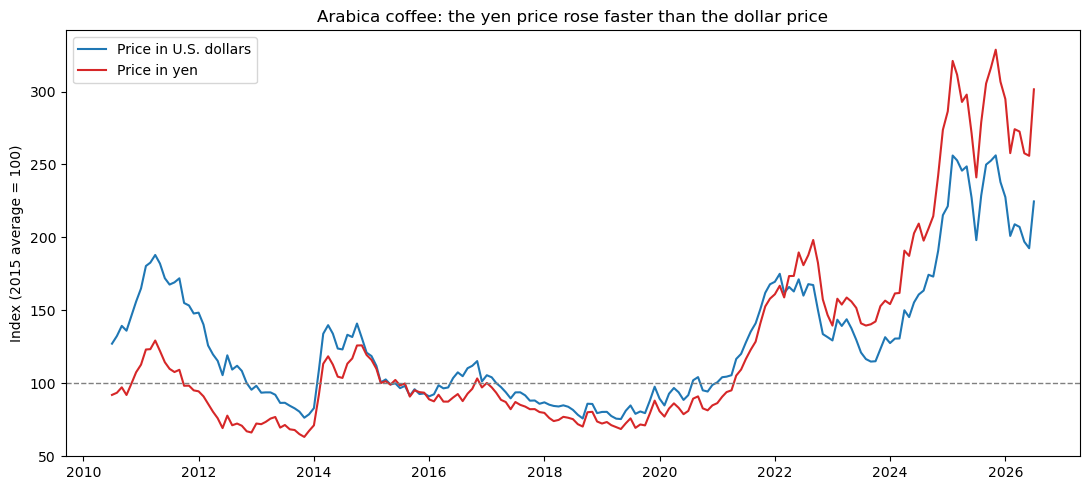

In [23]:
# Use the 2015 average as the baseline (2015 = 100)
base = fred[fred["month"].dt.year == 2015]

# Index each series: 100 means "same as the 2015 average", 200 means "double"
fred["arabica_usd_index"] = fred["arabica_usd_kg"] / base["arabica_usd_kg"].mean() * 100
fred["arabica_yen_index"] = fred["arabica_yen_kg"] / base["arabica_yen_kg"].mean() * 100

# Plot both lines on the same scale
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(fred["month"], fred["arabica_usd_index"], label="Price in U.S. dollars", color="tab:blue")
ax.plot(fred["month"], fred["arabica_yen_index"], label="Price in yen", color="tab:red")

# Reference line at 100 (the 2015 level)
ax.axhline(100, color="gray", linestyle="--", linewidth=1)

# Labels and title
ax.set_title("Arabica coffee: the yen price rose faster than the dollar price")
ax.set_ylabel("Index (2015 average = 100)")
ax.legend()
plt.tight_layout()
plt.show()